In [ ]:
# pip install squidpy


In [1]:
import scanpy as sc
import pandas as pd

import seaborn as sns
import numpy as np


import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.grid"] = False
plt.rcParams["axes.facecolor"] = 'white'
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

In [3]:
# sc.logging.print_versions()
# sc.set_figure_params(facecolor="white", figsize=(8, 8))
# sc.settings.verbosity = 3

In [2]:
# Import deconvoluted results
adata = sc.read_h5ad('Project2_Survival/deconvoluted_spatial_gene.h5ad')

In [5]:
adata

AnnData object with n_obs × n_vars = 2516 × 457
    obs: 'in_tissue', 'array_row', 'array_col', 'spot_', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts', 'clusters', '_indices', 'B-cells', 'CAFs', 'Cancer Epithelial', 'Endothelial', 'Myeloid', 'Normal Epithelial', 'PVL', 'Plasmablasts', 'T-cells'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'clusters_colors', 'dendrogram_clusters', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'spot__colors', 'umap'
    obsm: 'X_pca', 

In [6]:
# Where images save 

adata.uns['spatial']['Visium_FFPE_Human_Breast_Cancer']['images']['hires'].shape

(1839, 2000, 3)

In [7]:
SHAP_sign= [
    # 'CEBPB',
'SLC22A5',
'ME2',
'SCNN1A',
'RAB5C',
'CCNA1',
'KIF3A',
'LIMCH1',
# 'FOLH1',
'EDA2R',
'ANO6',
'FPR2',
'ZMYND8',
'GLS2',
'PHF20',
'BCL2A1',
'CNTNAP1',
'HK3',
'PGRMC1',
'CPSF4']
glyco_gene_list = ['ENO1', 'PPT1', 'GALM', 'HK2', 'PDHB', 'COQ2', 'HK3', 'PGAM2', 'DLD', 'BPGM', 'PDHA1', 'PGK1', 'FBP1', 'LDHA', 'DLAT', 'PFKP', 'HKDC1', 
                   'HK1', 'MINPP1', 'PGAM1', 'GAPDH', 'TPI1', 'ENO2', 'LDHB', 'PFKM', 'PCK2', 'PKM', 'ADPGK', 'ALDOA', 'LDHD', 'ENO3', 
                   'ALDOC', 'G6PC3', 'PHB', 'GPI', 'PFKL', 'GCK', 'LDHC', 'LDHAL6B']
marker_gene = list(set(SHAP_sign+glyco_gene_list) &set(adata.var.index))

In [ ]:
# Magic imputation
# import palantir
# dm_res = palantir.utils.run_diffusion_maps(adata, n_components=15)
# ms_data = palantir.utils.determine_multiscale_space(adata)
# imputed_X = palantir.utils.run_magic_imputation(adata)

c:\Users\minht\anaconda3\envs\pytorch-gpu\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


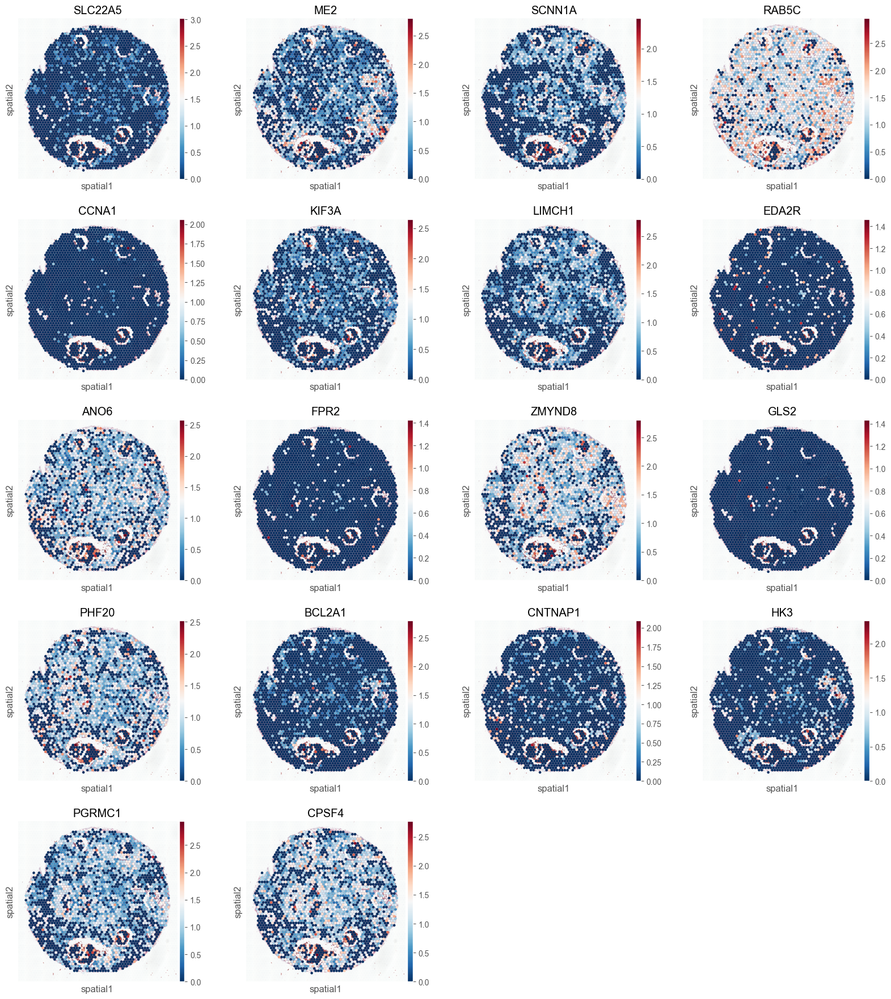

In [ ]:
# Plot spatial expression of SHAP_sign genes
sc.pl.spatial(
    adata,
    img_key="hires",
    color=SHAP_sign,
    # library_id=lib_a,
    cmap='RdBu_r',
    # layer= "counts",
    size=1.5,
    ncols=4,save=f"gene_all.png"
)

<h3> FLux analysis

In [ ]:
flux = pd.read_csv(r'Project2_Survival\Flux\spatial_gene_738811QB\spatial_gene_738811QB.csv', index_col=0)

# Module name
module_name = pd.read_csv(r'Project2_Survival\scfea\module_info_all_v1.csv', index_col=0)

# Import metadata
meta_data = pd.read_csv(r'Project2_Survival\Deconvolution_results.csv', index_col=0)


In [4]:
# Check data
print("Sample size before preprocesing", flux.shape)
print(flux.isna().sum().sum())
print(flux.index.duplicated().sum())

# Remove small variance
var_cal = flux.var()
flux = flux.loc[:, var_cal > 1e-8].abs()
print("Sample size", flux.shape)
# flux.var(axis=1).min()

# Order
# # Make it the same shape with transcriptomcsi data
flux = flux.loc[adata.obs.index,:] 

# Super_module :Aggreate by mean 
flux_sm = pd.merge(module_name['Supermodule_name'], flux.T, left_index=True, right_index=True).groupby('Supermodule_name').mean().T

#  Map name
# module_name['Name'] = module_name['Compound_IN_name'] + "_" + module_name['Compound_OUT_name']
map_id =  dict(zip(module_name.index.astype(str), module_name["Module_name"]))
flux = flux.rename(columns=map_id)

Sample size before preprocesing (2518, 168)
0
0
Sample size (2518, 31)


In [5]:
var_cal_sm = flux_sm.var()
flux_sm = flux_sm.loc[:, var_cal_sm > 1e-6]
print(flux_sm.shape)

(2516, 11)


In [6]:
cell_types = ['B-cells', 'CAFs',
       'Cancer Epithelial', 'Endothelial', 'Myeloid', 'Normal Epithelial',
       'PVL', 'Plasmablasts', 'T-cells']

In [7]:
# EDA
# Correalation
df_flux_sm =pd.merge(flux_sm, meta_data[cell_types], left_index=True, right_index=True)
# df_flux_sm.drop('cor', axis=1, inplace=True)
df_flux_sm_corr = df_flux_sm.corr().loc[flux_sm.columns, cell_types]
# df_flux_sm_corr.to_csv('Project2_Survival/Correlation/cell_type_flux_pathway_corr.csv')

In [ ]:
# EDA
# Correalation
df_flux =pd.merge(flux, meta_data[cell_types], left_index=True, right_index=True)
# df_flux_sm.drop('cor', axis=1, inplace=True)
df_flux_corr = df_flux.corr().loc[flux.columns, cell_types]
# df_flux_corr.to_csv('Results/cell_type_flux_corr.csv')

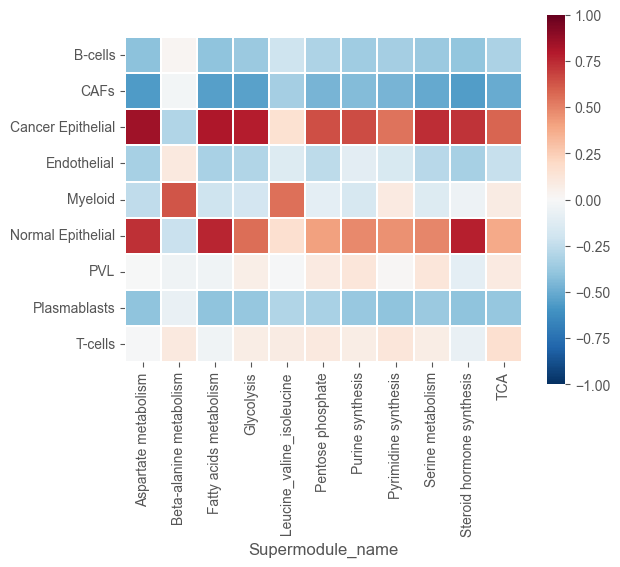

In [ ]:
# Correlation at pathway level
sns.heatmap(df_flux_sm_corr.T, cmap="RdBu_r", linewidth=0.1, linecolor='w', square=True, vmax=1, vmin=-1)
plt.savefig(f'Plot/correlation_pathway.pdf', dpi=300, bbox_inches='tight')

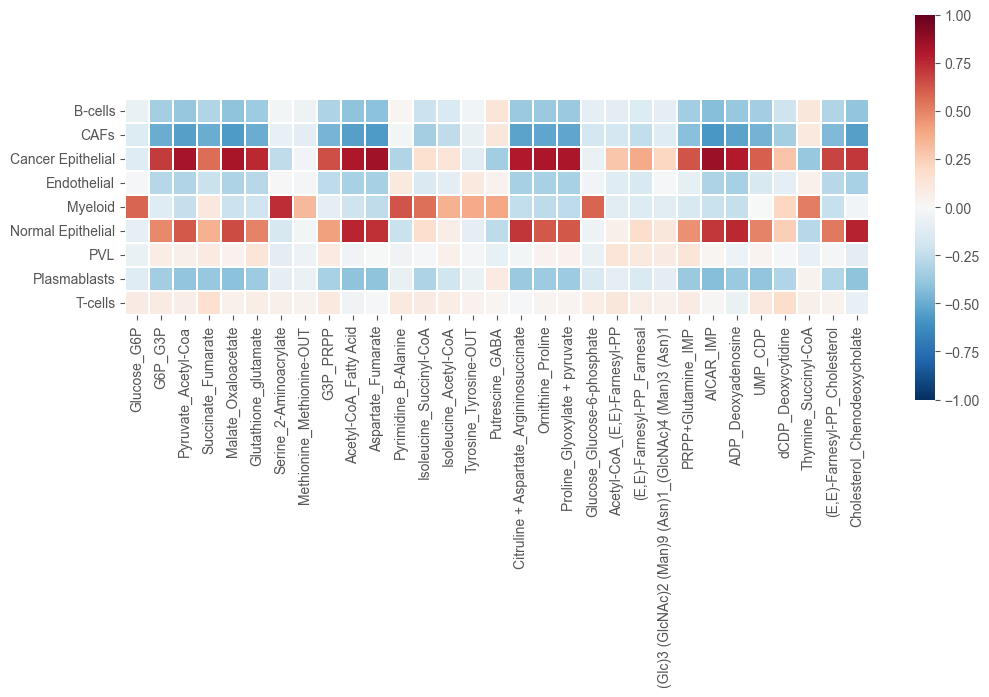

In [ ]:
# Correlation at reaction level
plt.figure(figsize=(12,5))
sns.heatmap(df_flux_corr.T, cmap="RdBu_r", linewidth=0.1, linecolor='w', square=True, vmax=1, vmin=-1)
plt.savefig(f'Plot/correlation_reaction.pdf', dpi=300, bbox_inches='tight')

In [ ]:
# Convert anadata
adata_flux = sc.AnnData(flux)
adata_flux.obs = adata_flux.obs.merge(meta_data, left_index=True, right_index=True)

adata_flux.obsm['spatial'] = adata.obsm['spatial'].copy()
adata_flux.uns['spatial'] =adata.uns['spatial'].copy()

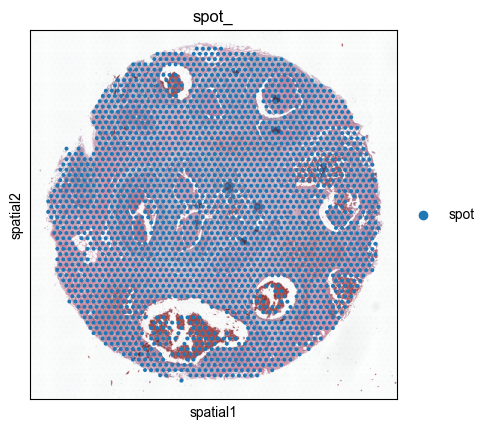

In [ ]:
# Plot spatial
sc.pl.spatial(adata_flux, color="spot_")

In [ ]:
# List the reactions
adata_flux.var.index

Index(['Glucose_G6P', 'G6P_G3P', 'Pyruvate_Acetyl-Coa', 'Succinate_Fumarate',
       'Malate_Oxaloacetate', 'Glutathione_glutamate',
       'Serine_2-Aminoacrylate', 'Methionine_Methionine-OUT', 'G3P_PRPP',
       'Acetyl-CoA_Fatty Acid', 'Aspartate_Fumarate', 'Pyrimidine_B-Alanine',
       'Isoleucine_Succinyl-CoA', 'Isoleucine_Acetyl-CoA',
       'Tyrosine_Tyrosine-OUT', 'Putrescine_GABA',
       'Citruline + Aspartate_Argininosuccinate', 'Ornithine_Proline',
       'Proline_Glyoxylate + pyruvate', 'Glucose_Glucose-6-phosphate',
       'Acetyl-CoA_(E,E)-Farnesyl-PP', '(E,E)-Farnesyl-PP_Farnesal',
       '(Glc)3 (GlcNAc)2 (Man)9 (Asn)1_(GlcNAc)4 (Man)3 (Asn)1',
       'PRPP+Glutamine_IMP', 'AICAR_IMP', 'ADP_Deoxyadenosine', 'UMP_CDP',
       'dCDP_Deoxycytidine', 'Thymine_Succinyl-CoA',
       '(E,E)-Farnesyl-PP_Cholesterol', 'Cholesterol_Chenodeoxycholate'],
      dtype='object')

In [ ]:
# Scale and normalize the metabolic flux data
adata_flux.layers['norm']= (adata_flux.X - adata_flux.X.min(axis=0)) / (adata_flux.X.max(axis=0) - adata_flux.X.min(axis=0))
adata_flux.layers['scale'] = sc.pp.scale(adata_flux.X, zero_center=False)

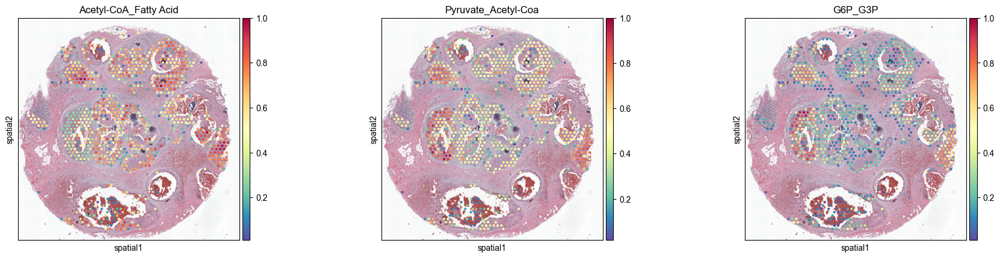

In [ ]:
# Plot spatial fluxomic for cancer epithelial cells
reaction= ['Acetyl-CoA_Fatty Acid', 'Pyruvate_Acetyl-Coa', "G6P_G3P"]
sc.pl.spatial(adata_flux[adata_flux.obs.cell_type.isin(['Cancer Epithelial']) ], color=reaction, layer="norm", cmap="Spectral_r", 
            #   save=f"Flux_spatial_{reaction}_cancer_epitalial.png"
              )

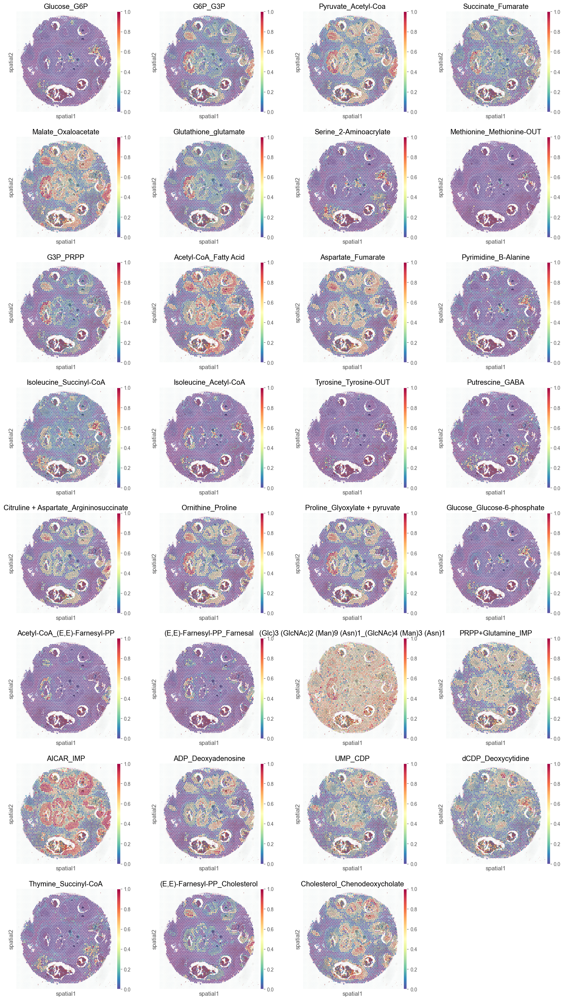

In [ ]:
# Plot all spatial fluxomic for cancer epithelial cells
sc.pl.spatial(adata_flux, color=adata_flux.var.index, layer="norm", cmap="Spectral_r", 
              save="Flux_spatial_cancer_epithelial.png")

<h3> Pathway level

In [16]:
# Convert anadata
adata_flu_sm = sc.AnnData(flux_sm)
adata_flu_sm.obs = adata_flu_sm.obs.merge(meta_data, left_index=True, right_index=True)
adata_flu_sm.obsm['spatial'] = adata.obsm['spatial'].copy()#adata_flux.obs[['array_row', 'array_col']].values
adata_flu_sm.uns['spatial'] =adata.uns['spatial'].copy()

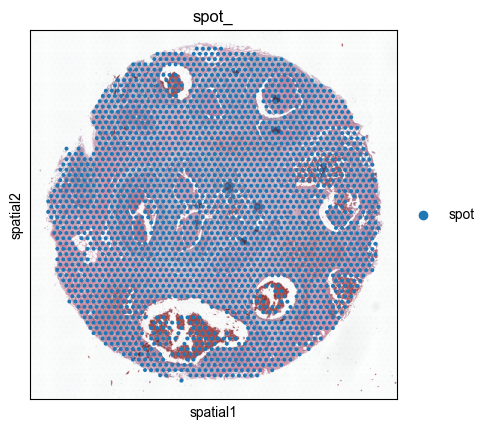

In [65]:
sc.pl.spatial(adata_flu_sm, color="spot_")

In [ ]:
# Scale and normalize the metabolic flux data
adata_flu_sm.layers['norm']= (adata_flu_sm.X - adata_flu_sm.X.min(axis=0)) / (adata_flu_sm.X.max(axis=0) - adata_flu_sm.X.min(axis=0))
adata_flu_sm.layers['scale'] = sc.pp.scale(adata_flu_sm.X, zero_center=False)

c:\Users\minht\anaconda3\envs\pytorch-gpu\lib\site-packages\anndata\_core\anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
c:\Users\minht\anaconda3\envs\pytorch-gpu\lib\site-packages\anndata\_core\anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


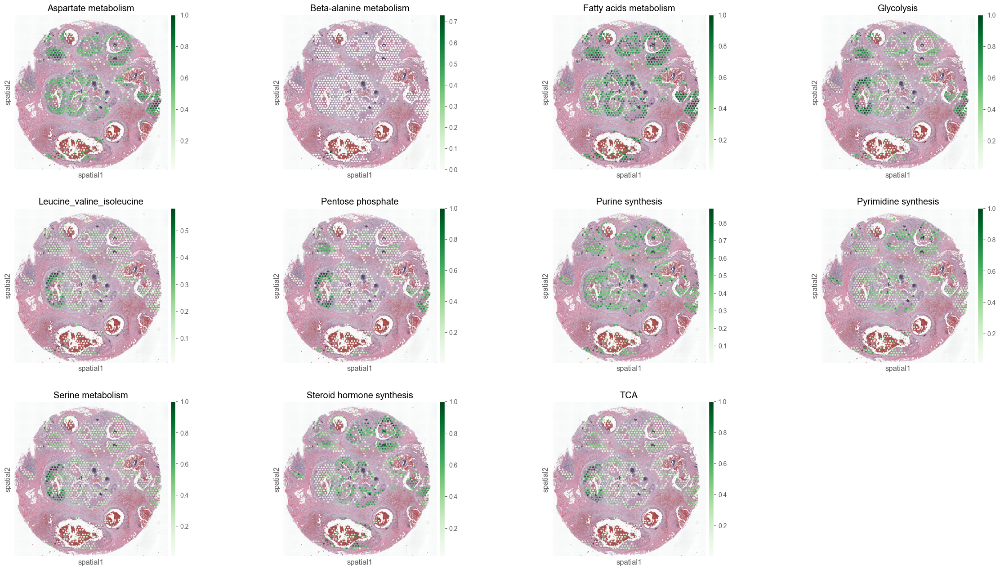

In [ ]:
# Plot all spatial fluxomic for cancer epithelial cells - at pathway level

sc.pl.spatial(adata_flu_sm[adata_flu_sm.obs.cell_type.isin(['Cancer Epithelial']) ], color=adata_flu_sm.var.index, layer="norm", cmap="Greens", 
              save=f"PathwayFlux_spatial_cancer_epithelial.pdf"
              )

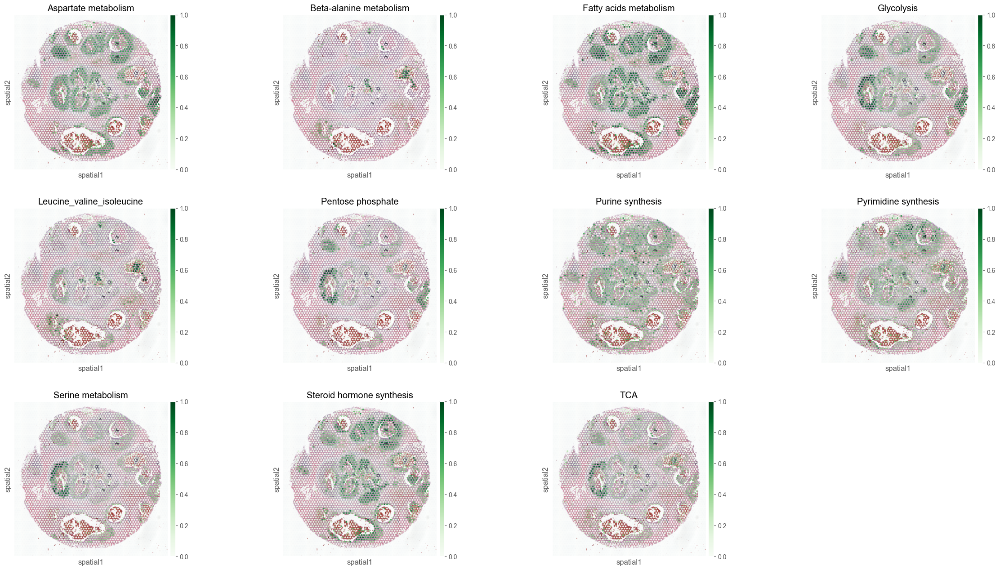

In [ ]:
# Plot all spatial fluxomic across tissue - at pathway level
sc.pl.spatial(adata_flu_sm, color=adata_flu_sm.var.index, layer="norm", cmap="Greens", 
              save="Pathway_Flux_spatial_across_tissue.png")

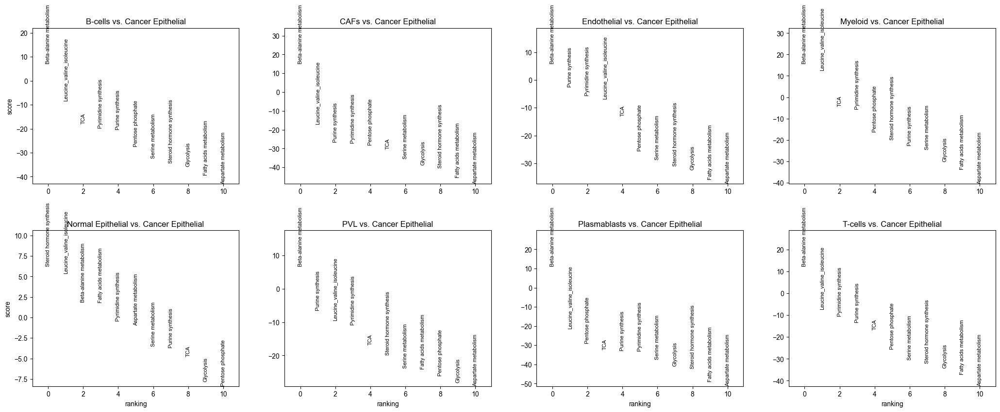

In [ ]:
# DE analysis
key_DE = "cell_type"
sc.tl.rank_genes_groups(adata_flu_sm, "cell_type", method="t-test", key_added=key_DE, reference="Cancer Epithelial")
sc.pl.rank_genes_groups(adata_flu_sm, n_genes=11, sharey=False,
                        key=key_DE,
                        save ="Pathway_DE_cancer.pdf"
                        )

results = adata_flu_sm.uns[key_DE]
('0', '1', '2', '3', '4')

out = np.array([[0,0,0,0,0]])
for group in results['names'].dtype.names:
    out = np.vstack((out, np.vstack((results['names'][group],
                                     results['scores'][group],
                                     results['pvals_adj'][group],
                                     results['logfoldchanges'][group],
                                     np.array([group] * len(results['names'][group])).astype('object'))).T))



markers = pd.DataFrame(out[1:], columns = ['Gene', 'scores', 'pval_adj', 'lfc', 'cluster'])
markers.to_csv('Pathway_lfc_vs_cancer_epi_cell.csv')